In [1]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import at3d
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import netCDF4 as nc
from collections import OrderedDict
from src.utils.util import load_sensor_dict
from src.utils.util import save_sensor_dict

In [2]:
## INPUT
obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'
background_scatterers_file = INTERIM_DATA / 'MIXTURE_default.nc'
config_file_name = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'misr_1D_config_I.json'
surface_wind_speed = 0.67 # m/s
# Reff(z) = a*z + b
a = 4.292 # um / km
b = 2.623 # um

cb = 0.4
ct = 0.7

# Mie table directory
mie_dir = PROJECT_ROOT / 'mie_tables'

## OUTPUT
out_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_I_RF17.nc'


In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
rte_grid = at3d.grid.make_grid(0.275, 3, 0.275, 3, rte_grid.z.data)
obs = load_sensor_dict(obs_file)

In [4]:
forward_sensors = at3d.containers.SensorsDict()
sensor = at3d.sensor.orthographic_projection(
    wavelength=0.67,
    bounding_box=rte_grid,
    x_resolution=0.275,
    y_resolution=0.275,
    azimuth=0,
    zenith=0,
    altitude='TOA',
    stokes='I',
    sub_pixel_ray_args={'method': None}
)
sensor = sensor.assign_attrs(mu0=obs['MISR']['sensor_list'][4].mu0)
sensor = sensor.assign_attrs(SAA=obs['MISR']['sensor_list'][4].SAA)
forward_sensors.add_sensor('MISR', sensor)

In [5]:
wavelength = 0.67

# Surface wind speed comes from ERA5 reanalysis - 
# see ./ancillary/CAMP2Ex_RF17_ERA5_Surface.ipynb
surfaces = OrderedDict()
m_water = 1.33197 - 1j*2.41e-8
surfaces[wavelength] = at3d.surface.wave_fresnel(np.real(m_water), np.imag(m_water), surface_wind_speed)

numerical_parameters = OrderedDict()
numerical_parameters[wavelength] = at3d.configuration.get_config(config_file_name)

sources = OrderedDict()
S0 = 1361 # W m^-2
r0 = 1 # AU
r = 1.00112201638005
E0 = (r0 / r)**2
F0 = E0 * S0
sources[wavelength] = at3d.source.solar(
    wavelength,
    -1*obs['MISR']['sensor_list'][0].mu0,
    obs['MISR']['sensor_list'][0].SAA,
    solarflux=F0,
    skyrad=0.0
)

background_optical_scatterers = OrderedDict()
merged_properties = xr.load_dataset(background_scatterers_file)
background_optical_scatterers[wavelength] = {}
background_optical_scatterers[wavelength]['background'] = merged_properties.isel(x=slice(0,3),y=slice(0,3))

mie_mono_table = at3d.mie.get_mono_table(
    'Water',
    (wavelength, wavelength),
    max_integration_radius=65.0,
    minimum_effective_radius=5.5,
    relative_dir=mie_dir,
    verbose=False
)
mie_mono_tables = OrderedDict()
mie_mono_tables[wavelength] = mie_mono_table
# mie_mono_table.to_netcdf('../mie_tables/red_mie_table.nc')

cloud_optical_prop_gen = at3d.medium.OpticalPropertyGenerator(
    'cloud',
    mie_mono_tables,
    at3d.size_distribution.gamma,
    particle_density=1.0,
    maxnphase=None,
    interpolation_mode='exact',
    density_normalization='geometric_extinction',
    reff=np.linspace(1, 30, 20),
    veff=np.linspace(0.01, 0.2, 5)
)


In [6]:
taus = np.logspace(-1, 1.9, 100)
taus[0] = 0
I = np.zeros(taus.shape)
tau_real = np.zeros(taus.shape)

for i, tau in enumerate(taus):
    cloud = rte_grid.copy(deep=True)
    i_low = np.argwhere(rte_grid.z.data >= cb)[0][0]
    i_up = np.argwhere(rte_grid.z.data <= ct)[-1][0]
    # print('cloud from {} km to {} km'.format(rte_grid.z.data[i_low], rte_grid.z.data[i_up]))
    thickness = rte_grid.z.data[i_up] - rte_grid.z.data[i_low]
    ext = np.zeros((rte_grid.dims['x'], rte_grid.dims['y'], rte_grid.dims['z']))
    ext[:, :, i_low:i_up] = tau/thickness
    cloud['density'] = (['x','y','z'], ext)
    # See ./ancillary/CAMP2Ex_SPEC.ipynb for Re calculation
    reff_profile = a * rte_grid.z.data + b
    reff = np.tile(reff_profile, (rte_grid.dims['x'], rte_grid.dims['y'], 1))
    cloud['reff'] = (['x','y','z'], reff)
    cloud['veff'] = (['x','y','z'], np.ones(cloud.density.shape) * 0.1)
    cloud_optical_properties = cloud_optical_prop_gen(cloud)

    medium = {}
    medium['background'] = merged_properties.isel(x=slice(0,3),y=slice(0,3))
    medium['cloud'] = cloud_optical_properties[wavelength]

    solvers = at3d.containers.SolversDict()
    solver = at3d.solver.RTE(
        numerical_params=numerical_parameters[wavelength],
        medium=medium,
        source=sources[wavelength],
        surface=surfaces[wavelength],
        num_stokes=1)
    solvers.add_solver(wavelength, solver)

    tau_real[i] = np.unique(solvers[0.67].medium['cloud'].extinction.integrate('z').data)[0]

    forward_sensors.get_measurements(solvers)

    cam = forward_sensors['MISR']['sensor_list'][0]
    assert len(np.unique(cam.I.data)) == 1
    I[i] = np.unique(cam.I.data)[0]

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.013  0.522E+02      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.493  0.529E+02      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.998  0.142E+02      144   256.00  1.000   [Radiance 0.670 micron]
     4  -2.039  0.138E+02      144   256.00  1.000   [Radiance 0.670 micron]
     5  -2.788  0.139E+02      144   256.00  1.000   [Radiance 0.670 micron]
     6  -3.206  0.139E+02      144   256.00  1.000   [Radiance 0.670 micron]
     7  -3.749  0.139E+02      144   256.00  1.000   [Radiance 0.670 micron]
     8  -4.039  0.139E+02      144   256.00  1.000   [Radiance 0.670 micron]
 ! Iterations:      8     Final Criterion:  0.000091   [Radiance 0.670 micron]
  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -1.018  0.522E+02      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.480  0.529E+02      135   256.00  1.000   [Radiance 0.670 micron]
   

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure_k9/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '8'. Max cell optical depth: '2.1116933822631836'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.883  0.234E+03      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.433  0.248E+03      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.678  0.254E+03      135   256.00  1.000   [Radiance 0.670 micron]
     4  -1.793  0.179E+03      144   256.00  1.000   [Radiance 0.670 micron]
     5  -1.585  0.813E+02      153   256.00  1.000   [Radiance 0.670 micron]
     6  -2.200  0.845E+02      153   256.00  1.000   [Radiance 0.670 micron]
     7  -2.460  0.850E+02      153   256.00  1.000   [Radiance 0.670 micron]
     8  -2.575  0.645E+02      171   256.00  1.000   [Radiance 0.670 micron]
     9  -2.187  0.585E+02      198   256.00  1.000   [Radiance 0.670 micron]
    10  -2.520  0.584E+02      198   256.00  1.000   [Radiance 0.670 micron]
    11  -2.654  0.533E+02      207   256.00  1.000   [Radiance 0.670 micron]
    12  -2.175  0.228E+02      234   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure_k9/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '8'. Max cell optical depth: '2.2578742504119873'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.885  0.247E+03      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.451  0.261E+03      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.702  0.267E+03      135   256.00  1.000   [Radiance 0.670 micron]
     4  -1.679  0.936E+02      153   256.00  1.000   [Radiance 0.670 micron]
     5  -2.012  0.913E+02      153   256.00  1.000   [Radiance 0.670 micron]
     6  -2.191  0.908E+02      153   256.00  1.000   [Radiance 0.670 micron]
     7  -2.341  0.686E+02      171   256.00  1.000   [Radiance 0.670 micron]
     8  -2.007  0.685E+02      171   256.00  1.000   [Radiance 0.670 micron]
     9  -2.869  0.685E+02      171   256.00  1.000   [Radiance 0.670 micron]
    10  -2.145  0.265E+02      234   256.00  1.000   [Radiance 0.670 micron]
    11  -2.278  0.245E+02      234   256.00  1.000   [Radiance 0.670 micron]
    12  -2.657  0.245E+02      234   256.00  1.000   [Radiance 0.670 micron]
  

...

  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.937  0.800E+03      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.710  0.795E+03      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.559  0.567E+03      144   256.00  1.000   [Radiance 0.670 micron]
     4  -1.511  0.297E+03      162   256.00  1.000   [Radiance 0.670 micron]
     5  -0.732  0.258E+03      180   256.00  1.000   [Radiance 0.670 micron]
     6  -1.358  0.263E+03      180   256.00  1.000   [Radiance 0.670 micron]
     7  -1.627  0.118E+03      225   256.00  1.000   [Radiance 0.670 micron]
     8  -1.803  0.130E+03      243   256.00  1.000   [Radiance 0.670 micron]
     9  -1.917  0.106E+03      252   256.00  1.000   [Radiance 0.670 micron]
    10  -2.076  0.109E+03      252   256.00  1.000   [Radiance 0.670 micron]
    11  -2.561  0.961E+02      261   256.00  1.000   [Radiance 0.670 micron]
    12  -2.501  0.650E+02      333   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure_k9/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '16'. Max cell optical depth: '33.297454833984375'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.937  0.802E+03      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.711  0.798E+03      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.553  0.578E+03      144   256.00  1.000   [Radiance 0.670 micron]
     4  -1.514  0.300E+03      162   256.00  1.000   [Radiance 0.670 micron]
     5  -0.726  0.252E+03      180   256.00  1.000   [Radiance 0.670 micron]
     6  -1.364  0.262E+03      180   256.00  1.000   [Radiance 0.670 micron]
     7  -1.626  0.121E+03      225   256.00  1.000   [Radiance 0.670 micron]
     8  -1.802  0.132E+03      243   256.00  1.000   [Radiance 0.670 micron]
     9  -1.921  0.104E+03      252   256.00  1.000   [Radiance 0.670 micron]
    10  -2.073  0.107E+03      252   256.00  1.000   [Radiance 0.670 micron]
    11  -2.477  0.912E+02      279   256.00  1.000   [Radiance 0.670 micron]
    12  -2.506  0.664E+02      333   256.00  1.000   [Radiance 0.670 micron]
  

/data/keeling/a/johntl3/miniconda3/envs/at3d_pure_k9/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '16'. Max cell optical depth: '35.619659423828125'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "


  ! Iter Log(Sol)  SplitCrit  Npoints  Nsh(avg)   [Radiance 0.670 micron]
     1  -0.938  0.804E+03      135   256.00  1.000   [Radiance 0.670 micron]
     2  -1.711  0.800E+03      135   256.00  1.000   [Radiance 0.670 micron]
     3  -1.548  0.589E+03      144   256.00  1.000   [Radiance 0.670 micron]
     4  -1.517  0.310E+03      162   256.00  1.000   [Radiance 0.670 micron]
     5  -0.712  0.248E+03      180   256.00  1.000   [Radiance 0.670 micron]
     6  -1.361  0.260E+03      180   256.00  1.000   [Radiance 0.670 micron]
     7  -1.620  0.124E+03      225   256.00  1.000   [Radiance 0.670 micron]
     8  -1.796  0.134E+03      243   256.00  1.000   [Radiance 0.670 micron]
     9  -1.922  0.108E+03      252   256.00  1.000   [Radiance 0.670 micron]
    10  -2.069  0.108E+03      252   256.00  1.000   [Radiance 0.670 micron]
    11  -2.311  0.902E+02      288   256.00  1.000   [Radiance 0.670 micron]
    12  -2.552  0.712E+02      324   256.00  1.000   [Radiance 0.670 micron]
  

In [7]:
LUT = xr.Dataset(
    coords=dict(
        I=I
    ),
    data_vars=dict(
        tau=(['I'], tau_real)
    )
)
assert np.all(np.diff(LUT.tau.data) > 0), "LUT tau not monotonic"
assert np.all(np.diff(LUT.I.data) > 0), "LUT I not monotonic"
LUT.to_netcdf(out_file)

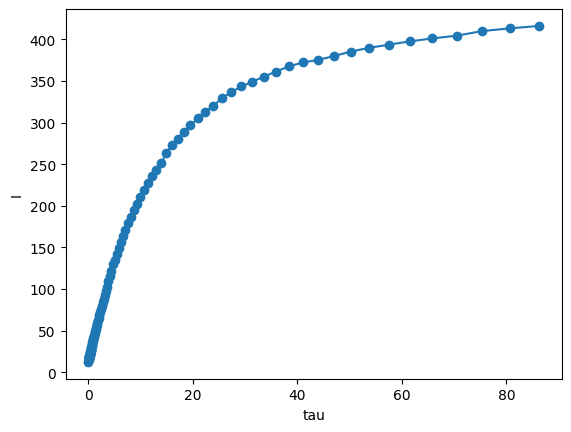

In [8]:
LUT.tau.plot(y='I', marker='o')